# Task 30 — Intrusion detection with unseen attacks: what the detector catches, and what the SOC pays for it

**Study unit:** ARI3217 — AI Enterprise Architectures and Transformation (University of Malta)
**Dataset:** [Network Intrusion dataset (CIC-IDS2017)](https://www.kaggle.com/datasets/chethuhn/network-intrusion-dataset) (flow features from five days of testbed traffic, July 2017)
**Task family:** tabular supervised and unsupervised detection, open-set evaluation, alert budgeting · **Companion task:** `02_card_fraud_tabular.ipynb` (the same honest-evaluation discipline on card transactions)

---

## The task card

> **Board question.** *Our security operations centre can triage 30 alerts an hour. If an attack type we have never seen arrives tomorrow, how much of it will the detector flag while the false alarms stay within those 30 — and is the ROC-AUC of 0.9985 from the first experiment the number to believe?*

**Business context.** A security operations centre (SOC) watches the flow records its sensors export: one row per connection, counts and timings, never content. Signature rules already catch known attacks; the ML detector is bought for the attack nobody has a rule for. Each flow is scored on export (Session 01's *online prediction* pattern, on a stream) and alerts go to tier-1 analysts (*human-in-the-loop*). The binding constraint is analyst attention: an overflowing queue gets ignored. Firewall, signature IDS, SIEM and ticketing stay; Milestone 1 shows where the model plugs in.

**What you will build from this notebook (see *Student tasks* at the end):**

1. the given **flow detector**, packaged and reproducible, evaluated by day on attack types it has never seen, with the traps guarded by tests;
2. an **operating point set from analyst capacity**, recorded as an ADR;
3. the **operational wrapper**: package, container, CI gate, registry, model card, monitoring plan;
4. an **ATT&CK knowledge layer** for alert triage, with its ablation;
5. a one-page **recommendation to the head of security operations**.

**Where this sits in the unit**

| Block | What this task exercises |
|---|---|
| 1 · EA for AI | Stream scoring beside signature IDS and the SIEM; analyst capacity; GDPR and flow logs |
| 2 · MLOps | Split by day, gate on recall at a fixed false-positive rate, alerts per hour and PSI (S04), registry (S06) |
| 3 · Semantic layer | MITRE ATT&CK as the knowledge base: coverage and alert enrichment |
| 4 · LLM/RAG | A triage note grounded in ATT&CK and the flow evidence (S10–S11) |

**Assessment.** A *worked baseline plus tasks*; marks follow `docs/task-rubric.md`. The model is given: you are marked on how you package, evaluate, deploy, monitor and govern it, not on improving it. The notebook contains **deliberate traps**, each flagged with ⚠ in the text; turning each into a test is part of the task.

**Honesty note.** The packets are **real**; the behaviour is **staged**: benign traffic from agents emulating 25 users, attacks run by the researchers at published times, almost all from one Kali Linux machine, each type once. Flow construction and labelling have documented errors (Engelen et al., 2021); several are measured below.

---

## How this notebook is organised

The notebook has three parts. Parts A and B are given; Part C is your assignment. **The model is given:** you package, evaluate, deploy and monitor it; you do not design, tune or replace it.

| Part | Sections | What it contains | What you do with it |
|---|---|---|---|
| **A · Explore the data** | 1–2 | Dataset card, first look and data quality | Read. Its quirks go into your model card and data contract. |
| **B · The given model** | 3–6 | Two detectors trained on Monday to Wednesday, the 30-alert operating point, the traps, ATT&CK as the knowledge base | Read, then package the code unchanged and reproduce its numbers (C2). |
| **C · Productionise it** | 7–10 | The detector after deployment, the module spine, student tasks, hand-in checklist | Your work: package, test, gate, track, serve, monitor, govern. Section 7 shows the silent failure your monitoring must catch. |

**What you need from Parts A and B**

- **Code to package:** `get_raw`, `clean_names` and `load_window` (Section 1); `fit_lgb`, `slog`, `at_budget` and `sweep` (Section 3); `per_segment` (Section 4); the ATT&CK mapping (Section 6); `psi` and `psi_cat` for monitoring (Section 7).
- **Parameters for `config/config.yaml`:** the CAPITALS in Section 0.
- **Numbers your pipeline must reproduce (C2):** 195,873 training flows (55,434 attacks), 140,748 benign calibration flows and 217,836 test flows (44,182 attacks) in the sample; a false-positive budget of 30 / 58,418 = 0.0514 % (LightGBM threshold 0.928); LightGBM macro recall 0.083 over the seven unseen types (DDoS 0.530) and macro ROC-AUC 0.857, split by day; 19–35 false alerts an hour on Thursday and Friday.
- **Runtime:** about 3–4 minutes on a laptop (187 s on the build machine).

## 0 · Setup

*Before Part A · the parameters below move into `config/config.yaml`.*

In [1]:
import os, json, time, warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
%matplotlib inline
import pyarrow as pa
import pyarrow.csv as pc
import lightgbm as lgb
import sklearn
from sklearn.ensemble import IsolationForest
from sklearn.metrics import roc_auc_score
from sklearn.model_selection import train_test_split

warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", message=".*does not have valid feature names.*")
pd.set_option("display.width", 140); pd.set_option("display.max_colwidth", 250)

# ---- parameters -------------------------------------------------------------
SEED = 3217
KAGGLE_HANDLE = "chethuhn/network-intrusion-dataset"
TRAIN_DAYS = ["Mon", "Tue", "Wed"]       # 3–5 July 2017: benign, brute force, DoS, Heartbleed
TEST_DAYS = ["Thu", "Fri"]               # 6–7 July 2017: web attacks, infiltration, botnet, port scan, DDoS — none seen in training
BENIGN_FRAC = 0.20                       # share of benign flows kept per file (uniform random); 0.10 on a small laptop
ATTACK_CAP = 20_000                      # attack flows kept per label; labels below the cap are kept whole
CALIB_FRAC = 0.50                        # share of the training days' sampled benign flows held out to set the threshold
ANALYST_CAPACITY_PER_HOUR = 30           # alerts the SOC can triage per hour (two tier-1 analysts on shift; see task C3)
CAPTURE_HOURS_PER_DAY = 8                # capture ran 09:00–17:00 each day (CIC's published schedule)
CAPTURE_FEATURES = ["Destination Port", "Init_Win_bytes_forward", "Init_Win_bytes_backward"]  # describe the testbed (Trap 3)

DATA_DIR = Path(os.environ.get("DATASETS_TASKS_DATA", Path.cwd().parent.parent / "data"))
RAW, PROCESSED = DATA_DIR / "raw" / "cicids2017", DATA_DIR / "processed"
RAW.mkdir(parents=True, exist_ok=True); PROCESSED.mkdir(parents=True, exist_ok=True)

SERIES = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100"]
INK, MUTED, GRID = "#0b0b0b", "#898781", "#e1e0d9"
plt.rcParams.update({
    "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb", "axes.edgecolor": "#c3c2b7",
    "axes.labelcolor": "#52514e", "xtick.color": MUTED, "ytick.color": MUTED, "text.color": INK,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.6, "axes.spines.top": False,
    "axes.spines.right": False, "font.size": 10, "axes.titlesize": 11, "axes.titleweight": "bold",
    "axes.titlelocation": "left", "legend.frameon": False, "figure.dpi": 110,
})
np.random.seed(SEED)
T_START = time.time()

def show(df, spec=None, default="{:.3f}"):
    """Format numbers as text for display: column → format string (no Styler, so no jinja2 needed)."""
    spec, out = spec or {}, df.astype(object).copy()
    for c in df.columns:
        f = spec.get(c, default)
        out[c] = [v if isinstance(v, (str, bool, np.bool_)) else ("" if pd.isna(v) else f.format(v)) for v in df[c]]
    return out

print(f"pandas {pd.__version__} · lightgbm {lgb.__version__} · scikit-learn {sklearn.__version__} · numpy {np.__version__}")

pandas 3.1.0 · lightgbm 4.7.0 · scikit-learn 1.9.1 · numpy 2.5.4


# Part A — Explore the data

*Sections 1–2: read them; the quirks they find go into your model card and data contract.*

## 1 · Dataset card

*Part A · Explore · read; package `get_raw`, `clean_names` and `load_window`; no address column is ever read.*

| Field | Value |
|---|---|
| **Source** | Kaggle `chethuhn/network-intrusion-dataset`: the `MachineLearningCVE` CSVs of CIC-IDS2017 (Canadian Institute for Cybersecurity; Sharafaldin et al., 2018) |
| **Licence** | CC0 on the Kaggle copy, but the uploader says he is not the owner: follow CIC's terms (use with a citation of the dataset and paper) |
| **Provenance** | Staged testbed, 3–7 July 2017, 09:00–17:00; flows built by CICFlowMeter, labelled from the attack schedule |
| **Size** | 2,830,743 flows, 557,646 of them attacks (19.7 %), under 14 attack labels; 885 MB |
| **Files** | one CSV per day; Thursday and Friday split into morning and afternoon files |
| **Schema** | 78 numeric columns (counts, lengths, inter-arrival times, flags, initial TCP windows, `Destination Port`) plus `Label`; **no flow ID, IP address or timestamp** |
| **Label** | `BENIGN` or an attack label; each attack type on one day only |
| **Window used here** | All five days; train Monday–Wednesday, test Thursday–Friday. Sample: 20 % of benign flows per file, attack flows up to 20,000 per label (554,457 flows, 197 MB), weighted back to all traffic; lower `BENIGN_FRAC` on a small laptop |
| **PII** | None in this copy. Production feeds carry IP addresses, which can be personal data under GDPR (CJEU, *Breyer*, C‑582/14); the loader never reads such columns |

**Known quirks you must handle (and should mention in your model card):**

1. ⚠ **Attack types are scheduled by day**, so a split by day tests on types never seen — the board's question.
2. ⚠ **Duplicates and contradictions**: one flow in nine is a copy; hundreds of feature vectors carry two labels.
3. **Infinite, missing, impossible and dead values**, and garbled labels (`Web Attack � Brute Force`): handled on load, counted in Section 2.
4. ⚠ **Labels that do not match the flow**, in both directions: attack flows that carry no payload, and attack traffic labelled benign (Trap 4).
5. ⚠ **Columns that describe the testbed**: one target server, one attacker operating system, shared ports (Trap 3).
6. **No clock**: no timestamp, and the row order is not one (Section 2); the time axis is the day and the half-day file.

In [2]:
FILES = [  # (file, day, segment) in capture order; Thursday and Friday are split into morning and afternoon files
    ("Monday-WorkingHours.pcap_ISCX.csv", "Mon", "Mon"),
    ("Tuesday-WorkingHours.pcap_ISCX.csv", "Tue", "Tue"),
    ("Wednesday-workingHours.pcap_ISCX.csv", "Wed", "Wed"),
    ("Thursday-WorkingHours-Morning-WebAttacks.pcap_ISCX.csv", "Thu", "Thu am"),
    ("Thursday-WorkingHours-Afternoon-Infilteration.pcap_ISCX.csv", "Thu", "Thu pm"),
    ("Friday-WorkingHours-Morning.pcap_ISCX.csv", "Fri", "Fri am"),
    ("Friday-WorkingHours-Afternoon-PortScan.pcap_ISCX.csv", "Fri", "Fri pm-1"),
    ("Friday-WorkingHours-Afternoon-DDos.pcap_ISCX.csv", "Fri", "Fri pm-2"),
]
PERSONAL = ["Flow ID", "Source IP", "Src IP", "Destination IP", "Dst IP", "Source Port", "Src Port", "Timestamp"]

def get_raw(filename: str) -> Path:
    local = RAW / filename
    if local.exists():
        return local
    import kagglehub
    return Path(kagglehub.dataset_download(KAGGLE_HANDLE, path=filename))

def clean_names(path: Path) -> list:
    """Header names without the leading spaces; the second 'Fwd Header Length' becomes 'Fwd Header Length.1'."""
    out = []
    for c in open(path, encoding="utf-8").readline().rstrip("\r\n").split(","):
        c = c.strip()
        out.append(c + ".1" if c in out else c)
    return out

def load_window():
    """Read each day's CSV once: quality statistics and a 64-bit fingerprint for EVERY flow, then a stated sample."""
    c_flows, c_index, c_quality = (PROCESSED / f"30_{n}" for n in ["flows_sample.parquet", "flow_index.parquet", "quality.json"])
    if c_flows.exists() and c_index.exists() and c_quality.exists():
        return pd.read_parquet(c_flows), pd.read_parquet(c_index), json.load(open(c_quality))
    t = time.time()
    samples, index = [], []
    q = {"inf": {}, "nan": {}, "neg": {}, "min": {}, "max": {}, "dup_col_identical": True, "personal_found": []}
    for k, (fname, day, seg) in enumerate(FILES):
        path = get_raw(fname)
        names = clean_names(path)
        q["personal_found"] += [c for c in names if c in PERSONAL]
        feats = [c for c in names if c != "Label" and c not in PERSONAL]      # governance: personal columns are never read
        tbl = pc.read_csv(path, read_options=pc.ReadOptions(column_names=names, skip_rows=1),
                          convert_options=pc.ConvertOptions(include_columns=feats + ["Label"],
                                                            column_types={**{c: pa.float64() for c in feats}, "Label": pa.string()}))
        df = tbl.to_pandas(); del tbl
        label = df.pop("Label").str.replace("�", "–", regex=False).str.strip()   # the en dash was lost upstream
        n = len(df)
        # ---- quality on the full file, before any sampling ----
        for name_, mask in [("inf", np.isinf(df)), ("nan", df.isna()), ("neg", df < 0)]:
            for c, v in mask.sum().items():
                if v:
                    q[name_][c] = q[name_].get(c, 0) + int(v)
        finite = df.replace([np.inf, -np.inf], np.nan)
        for c, v in finite.min().items():
            q["min"][c] = min(q["min"].get(c, np.inf), float(v))
        for c, v in finite.max().items():
            q["max"][c] = max(q["max"].get(c, -np.inf), float(v))
        q["dup_col_identical"] &= bool(df["Fwd Header Length"].equals(df["Fwd Header Length.1"]))
        fp = pd.util.hash_pandas_object(df, index=False).to_numpy()            # one fingerprint per flow (features only)
        zero_payload = ((df["Total Length of Fwd Packets"] + df["Total Length of Bwd Packets"]) == 0).to_numpy()
        index.append(pd.DataFrame({"seg": np.int8(k), "pos": (np.arange(n) / n).astype("float32"), "label": label.to_numpy(),
                                   "fp": fp, "zero_payload": zero_payload}))
        # ---- sampling rule: BENIGN_FRAC of benign flows, every attack flow up to ATTACK_CAP per label ----
        rng = np.random.default_rng(SEED + k)
        keep, weight = np.zeros(n, bool), np.ones(n, "float32")
        for lab_, idx in pd.Series(np.arange(n)).groupby(label.to_numpy()):
            idx = idx.to_numpy()
            if lab_ == "BENIGN":
                pick = idx[rng.random(len(idx)) < BENIGN_FRAC]
            else:
                pick = rng.choice(idx, ATTACK_CAP, replace=False) if len(idx) > ATTACK_CAP else idx
            keep[pick] = True; weight[pick] = len(idx) / len(pick)          # weight scales counts back to all traffic
        s = df.loc[keep].astype("float32")
        s.insert(0, "label", label.to_numpy()[keep]); s.insert(0, "weight", weight[keep])
        s.insert(0, "pos", (np.flatnonzero(keep) / n).astype("float32")); s.insert(0, "seg", np.int8(k))
        s.insert(0, "fp", fp[keep]); s.insert(0, "zero_payload", zero_payload[keep])
        samples.append(s)
        del df, finite
    flows, idx_ = pd.concat(samples, ignore_index=True), pd.concat(index, ignore_index=True)
    for d in (flows, idx_):
        d["label"] = d["label"].astype("category")
    flows.to_parquet(c_flows); idx_.to_parquet(c_index); json.dump(q, open(c_quality, "w"))
    print(f"read {len(FILES)} files and built the caches in {time.time() - t:.0f}s")
    return flows, idx_, q

flows, flow_index, quality = load_window()
SEG_NAME = {k: s for k, (_, _, s) in enumerate(FILES)}
SEG_DAY = {k: d for k, (_, d, _) in enumerate(FILES)}
for d in (flows, flow_index):
    d["segment"] = d.seg.map(SEG_NAME)
    d["day"] = d.seg.map(SEG_DAY)

n_attack = int((flow_index.label != "BENIGN").sum())
raw_mb = sum((RAW / f).stat().st_size for f, _, _ in FILES if (RAW / f).exists()) / 1e6
print(f"{len(flow_index):,} flows in {len(FILES)} files ({raw_mb:,.0f} MB of CSV) · {n_attack:,} attack flows ({n_attack / len(flow_index):.1%}) "
      f"under {flow_index.label.nunique() - 1} attack labels · sample kept: {len(flows):,} flows "
      f"({flows.memory_usage(deep=True).sum() / 1e6:.0f} MB) · personal columns found: {quality['personal_found'] or 'none'}")
flows.label.value_counts().rename("flows in the sample").to_frame().T

2,830,743 flows in 8 files (885 MB of CSV) · 557,646 attack flows (19.7%) under 14 attack labels · sample kept: 554,457 flows (197 MB) · personal columns found: none


label,BENIGN,DDoS,DoS Hulk,PortScan,DoS GoldenEye,FTP-Patator,SSH-Patator,DoS slowloris,DoS Slowhttptest,Bot,Web Attack – Brute Force,Web Attack – XSS,Infiltration,Web Attack – Sql Injection,Heartbleed
flows in the sample,454841,20000,20000,20000,10293,7938,5897,5796,5499,1966,1507,652,36,21,11


## 2 · First look

*Part A · Explore · read; the data-quality table goes into your model card and data contract.*

What a SOC lead asks first: what happened on which day, how large was it, and what does *normal* look like from day to day. The table uses every flow. `est. hours` uses benign volume as the clock: a file holding a third of Thursday's benign flows is taken to cover a third of Thursday's eight hours.

In [3]:
FAMILY = {"BENIGN": "benign", "FTP-Patator": "brute force", "SSH-Patator": "brute force",
          "DoS slowloris": "DoS / DDoS", "DoS Slowhttptest": "DoS / DDoS", "DoS Hulk": "DoS / DDoS",
          "DoS GoldenEye": "DoS / DDoS", "DDoS": "DoS / DDoS", "Heartbleed": "exploit, infiltration, bot",
          "Infiltration": "exploit, infiltration, bot", "Bot": "exploit, infiltration, bot",
          "Web Attack – Brute Force": "web attack", "Web Attack – XSS": "web attack",
          "Web Attack – Sql Injection": "web attack", "PortScan": "port scan"}
seg_order = [s for _, _, s in FILES]
benign_seg = flow_index[flow_index.label == "BENIGN"].groupby("seg").size()
benign_day = benign_seg.groupby(benign_seg.index.map(SEG_DAY)).transform("sum")
SEG_HOURS = (CAPTURE_HOURS_PER_DAY * benign_seg / benign_day).rename(index=SEG_NAME)   # benign volume as the clock

def attack_list(s):
    vc = s[s != "BENIGN"].value_counts()
    return ", ".join(f"{k} {v:,}" for k, v in vc.items() if v > 0) or "—"

schedule = flow_index.groupby("seg").agg(day=("day", "first"), flows=("label", "size"),
                                         attack_flows=("label", lambda s: int((s != "BENIGN").sum())),
                                         attack_labels=("label", attack_list))
schedule.index = schedule.index.map(SEG_NAME)
schedule.insert(1, "est. hours", SEG_HOURS.round(1))
schedule.insert(2, "role", np.where(schedule.day.isin(TRAIN_DAYS), "train", "test (unseen types)"))
display(show(schedule, {"flows": "{:,}", "attack_flows": "{:,}", "est. hours": "{:.1f}"}))

,day,est. hours,role,flows,attack_flows,attack_labels
seg,,,,,,
Mon,Mon,8.0,train,"529,918",0,—
Tue,Tue,8.0,train,"445,909","13,835","FTP-Patator 7,938, SSH-Patator 5,897"
Wed,Wed,8.0,train,"692,703","252,672","DoS Hulk 231,073, DoS GoldenEye 10,293, DoS slowloris 5,796, DoS Slowhttptest 5,499, Heartbleed 11"
Thu am,Thu,2.9,test (unseen types),"170,366","2,180","Web Attack – Brute Force 1,507, Web Attack – XSS 652, Web Attack – Sql Injection 21"
Thu pm,Thu,5.1,test (unseen types),"288,602",36,Infiltration 36
Fri am,Fri,3.7,test (unseen types),"191,033","1,966","Bot 1,966"
Fri pm-1,Fri,2.5,test (unseen types),"286,467","158,930","PortScan 158,930"
Fri pm-2,Fri,1.9,test (unseen types),"225,745","128,027","DDoS 128,027"


benign share by file · DNS: Mon 41% Tue 44% Wed 44% Thu am 46% Thu pm 35% Fri am 48% Fri pm-1 46% Fri pm-2 33% · HTTPS: Mon 27% Tue 22% Wed 23% Thu am 21% Thu pm 18% Fri am 21% Fri pm-1 21% Fri pm-2 14%


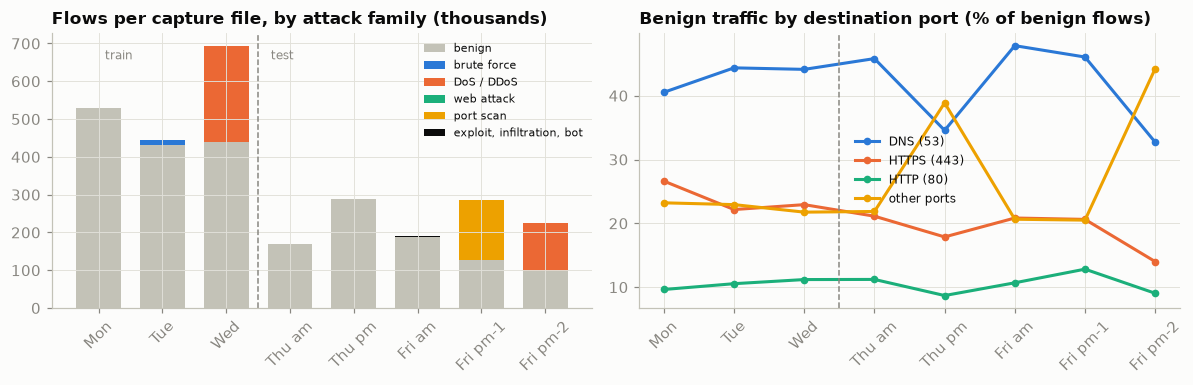

In [4]:
fam_colors = {"benign": "#c3c2b7", "brute force": SERIES[0], "DoS / DDoS": SERIES[1], "web attack": SERIES[2],
              "port scan": SERIES[3], "exploit, infiltration, bot": INK}
mix = (flow_index.assign(family=flow_index.label.astype(str).map(FAMILY))
       .groupby(["segment", "family"]).size().unstack(fill_value=0).reindex(seg_order))
ben = flows[flows.label == "BENIGN"]
port_grp = np.select([ben["Destination Port"] == 53, ben["Destination Port"] == 443, ben["Destination Port"] == 80],
                     ["DNS (53)", "HTTPS (443)", "HTTP (80)"], "other ports")
portmix = pd.crosstab(ben.segment, port_grp, normalize="index").reindex(seg_order)

fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
ax = axes[0]
bottom = np.zeros(len(mix))
for fam in fam_colors:
    if fam in mix:
        ax.bar(mix.index, mix[fam] / 1e3, bottom=bottom, color=fam_colors[fam], label=fam, width=0.7)
        bottom += mix[fam].to_numpy() / 1e3
ax.axvline(2.5, color=MUTED, ls="--", lw=1)
ax.text(0.1, bottom.max() * 0.95, "train", color=MUTED, fontsize=8); ax.text(2.7, bottom.max() * 0.95, "test", color=MUTED, fontsize=8)
ax.set_title("Flows per capture file, by attack family (thousands)"); ax.legend(fontsize=7, loc="upper right")
ax.tick_params(axis="x", rotation=45)
ax = axes[1]
for i, c in enumerate(["DNS (53)", "HTTPS (443)", "HTTP (80)", "other ports"]):
    ax.plot(portmix.index, portmix[c] * 100, "-o", ms=4, lw=2, color=(SERIES + [MUTED])[i], label=c)
ax.axvline(2.5, color=MUTED, ls="--", lw=1)
ax.set_title("Benign traffic by destination port (% of benign flows)"); ax.legend(fontsize=8); ax.tick_params(axis="x", rotation=45)
plt.tight_layout()
print("benign share by file · DNS:", " ".join(f"{s} {v:.0%}" for s, v in portmix["DNS (53)"].items()),
      "· HTTPS:", " ".join(f"{s} {v:.0%}" for s, v in portmix["HTTPS (443)"].items()))

The attacks that matter are invisible in the volume: the web attacks, the infiltration and the botnet are each a sliver of their file. Benign traffic is not stationary either: DNS is 41–48 % of benign flows in six files but 35 % on Thursday afternoon and 33 % in the DDoS file. Keep those two files in mind for Trap 4 and Section 7.

### Data quality is a finding, not a chore

Every check runs on all 2.83 M flows, before sampling, and belongs in the model card.

In [5]:
fi_lab = flow_index.label.astype(str)
dup_exact = flow_index.duplicated(["fp", "label"])
n_lab_per_fp = flow_index.groupby("fp").label.nunique()
conflict_fp = n_lab_per_fp.index[n_lab_per_fp > 1]
in_conflict = flow_index.fp.isin(conflict_fp)
CONSTANT = [c for c in quality["min"] if quality["min"][c] == quality["max"][c]]
dq = pd.DataFrame({"value": [
    f"{dup_exact.sum():,} ({dup_exact.mean():.1%})",
    f"{len(conflict_fp):,} vectors · {in_conflict.sum():,} flows ({int((in_conflict & (fi_lab != 'BENIGN')).sum()):,} labelled as attacks)",
    f"Flow Bytes/s {quality['inf']['Flow Bytes/s']:,} · Flow Packets/s {quality['inf']['Flow Packets/s']:,}",
    f"Flow Bytes/s {quality['nan']['Flow Bytes/s']:,}",
    f"Flow Duration {quality['neg']['Flow Duration']:,} · Flow IAT Min {quality['neg']['Flow IAT Min']:,}",
    f"forward {quality['neg']['Init_Win_bytes_forward']:,} · backward {quality['neg']['Init_Win_bytes_backward']:,}",
    f"{len(CONSTANT)}: " + ", ".join(CONSTANT),
    f"Fwd Header Length appears twice; identical in every file: {quality['dup_col_identical']}",
]}, index=["exact duplicate flows (same features, same label)", "identical feature vectors with different labels",
           "infinite values", "missing values", "negative durations / inter-arrival times",
           "Init_Win_bytes = −1 (no window observed)", "constant columns (all zero)", "duplicated column"])
display(dq)

by_label = flow_index.assign(dup=dup_exact, conflict=in_conflict).groupby("label", observed=True).agg(
    flows=("fp", "size"), exact_duplicates=("dup", "mean"), zero_payload=("zero_payload", "mean"), conflicting=("conflict", "mean"))
by_label = by_label.sort_values("flows", ascending=False)
display(show(by_label, {"flows": "{:,}", "exact_duplicates": "{:.1%}", "zero_payload": "{:.1%}", "conflicting": "{:.2%}"}))

,value
"exact duplicate flows (same features, same label)","308,381 (10.9%)"
identical feature vectors with different labels,"698 vectors · 7,020 flows (6,284 labelled as attacks)"
infinite values,"Flow Bytes/s 1,509 · Flow Packets/s 2,867"
missing values,"Flow Bytes/s 1,358"
negative durations / inter-arrival times,"Flow Duration 115 · Flow IAT Min 2,891"
Init_Win_bytes = −1 (no window observed),"forward 1,001,189 · backward 1,441,552"
constant columns (all zero),"8: Bwd PSH Flags, Bwd URG Flags, Fwd Avg Bytes/Bulk, Fwd Avg Packets/Bulk, Fwd Avg Bulk Rate, Bwd Avg Bytes/Bulk, Bwd Avg Packets/Bulk, Bwd Avg Bulk Rate"
duplicated column,Fwd Header Length appears twice; identical in every file: True


,flows,exact_duplicates,zero_payload,conflicting
label,,,,
BENIGN,"2,273,097",7.8%,12.3%,0.03%
DoS Hulk,"231,073",25.2%,28.5%,2.26%
PortScan,"158,930",42.9%,0.3%,0.66%
DDoS,"128,027",0.0%,0.0%,0.00%
DoS GoldenEye,"10,293",0.1%,25.1%,0.00%
FTP-Patator,"7,938",25.3%,0.2%,0.00%
SSH-Patator,"5,897",45.4%,49.5%,0.00%
DoS slowloris,"5,796",7.1%,28.4%,0.02%
DoS Slowhttptest,"5,499",4.9%,51.3%,0.00%


In [6]:
# Is the row order a clock? Median flow duration (ms) by tenth of each file, and where Wednesday's GoldenEye flows sit
flows["decile"] = np.minimum((flows.pos * 10).astype(int), 9)
dur = (flows.groupby(["segment", "decile"])["Flow Duration"].median() / 1e3).unstack().reindex(seg_order)
display(dur.round(1))
wed = flow_index[flow_index.segment == "Wed"]
for lab_, window in [("DoS GoldenEye", "11:10–11:23"), ("Heartbleed", "15:12–15:32")]:
    p = wed.loc[wed.label == lab_, "pos"]
    print(f"Wed · {lab_:13s} published {window}: {len(p):,} flows, {(p >= 0.75).mean():.0%} of them in the last quarter of the file")

decile,0,1,2,3,4,5,6,7,8,9
segment,,,,,,,,,,
Mon,255.8,97.4,83.8,81.5,60.6,60.8,23.2,0.2,0.2,0.2
Tue,189.4,85.5,66.5,71.2,78.9,60.5,0.5,0.2,0.2,0.2
Wed,3002.1,63118.7,85173.6,85452.2,134.8,68.7,61.2,31.9,23.7,23.7
Thu am,31.2,33.3,50.4,41.3,61.3,31.0,32.5,47.8,32.5,41.8
Thu pm,31.3,30.7,23.8,25.4,0.1,0.1,0.1,0.1,31.4,32.4
Fri am,37.5,47.9,46.6,31.1,30.7,30.6,31.1,31.5,36.2,31.4
Fri pm-1,31.4,31.0,30.5,0.0,0.0,0.0,0.0,0.0,0.2,0.3
Fri pm-2,50.6,1446.9,2016.0,3667.6,5577.9,3197.5,1839.7,1839.1,1031.6,36.7


Wed · DoS GoldenEye published 11:10–11:23: 10,293 flows, 87% of them in the last quarter of the file
Wed · Heartbleed    published 15:12–15:32: 11 flows, 100% of them in the last quarter of the file


What the checks mean for the model. **Duplicates** concentrate in the volumetric attacks (42.9 % of PortScan, 45.4 % of SSH-Patator, 25.2 % of DoS Hulk), so a random split puts copies on both sides (Trap 2). **Payload-less attack flows** are 90.0 % of web brute force and 96.3 % of XSS (Trap 4). **Contradictions**: 2.26 % of DoS Hulk flows have an identical twin with another label. Infinities become missing values, not dropped rows: the service will receive such flows and must answer.

The duration table settles the clock question. Monday's and Tuesday's median flow lasts tens of milliseconds for six or seven tenths of the file and 0.2–0.5 ms after that — a separate block, not a quiet evening. Wednesday's GoldenEye attack, published for 11:10–11:23, has 87 % of its flows in the last quarter of the file, beside the 15:12 Heartbleed. The row order is export order, so no hour-of-day features and no "last hour as validation" split.

# Part B — The given model

*Sections 3–6: read them, then package the code unchanged and reproduce its numbers (C2). You do not change the method.*

## 3 · Two detectors, trained on Monday to Wednesday

*Part B · Given model · package `fit_lgb`, `slog`, `at_budget` and `sweep`; reproduce the macro recall (C2); the random split is reference only.*

One rule: **nothing from Thursday or Friday touches the model or its threshold.**

- **Features**: the 66 columns left after dropping the dead ones; infinities become missing. The three capture features are held back (Trap 3).
- **LightGBM**, attack against benign, knowing seven attack labels.
- **Isolation Forest** on benign training flows only (signed log transform): the textbook answer to "unseen attacks".
- **Threshold from capacity**: 30 alerts an hour over 58,418 benign flows an hour gives the false-positive budget; the threshold is that quantile of scores on held-out benign training-day flows (held out at random, as there is no clock).
- **Metric**: recall per unseen type at that threshold, macro-averaged so that 36 infiltration flows count as much as 128,027 DDoS flows; ROC-AUC as a threshold-free check. Alongside, LightGBM on a **random 70/30 split**: the careless number.

In [7]:
META = ["zero_payload", "fp", "seg", "pos", "weight", "label", "segment", "day", "decile"]
ALL_FEATURES = [c for c in flows.columns if c not in META + CONSTANT + ["Fwd Header Length.1"]]
FEATURES = [c for c in ALL_FEATURES if c not in CAPTURE_FEATURES]
X = flows[ALL_FEATURES].replace([np.inf, -np.inf], np.nan)          # inf = division by a zero duration: treat as missing
y = (flows.label != "BENIGN").to_numpy().astype(int)
label = flows.label.astype(str).to_numpy()
w = flows.weight.to_numpy()
train_d = flows.day.isin(TRAIN_DAYS).to_numpy()
test_d = flows.day.isin(TEST_DAYS).to_numpy()
rng = np.random.default_rng(SEED)
calib = train_d & (y == 0) & (rng.random(len(y)) < CALIB_FRAC)    # benign flows never trained on: they set the threshold
fit = train_d & ~calib
SEEN = sorted(set(label[fit & (y == 1)]))
UNSEEN = sorted(set(label[test_d & (y == 1)]))
benign_per_hour_train = int((flow_index.day.isin(TRAIN_DAYS) & (flow_index.label == "BENIGN")).sum()) / (len(TRAIN_DAYS) * CAPTURE_HOURS_PER_DAY)
benign_per_hour_test = int((flow_index.day.isin(TEST_DAYS) & (flow_index.label == "BENIGN")).sum()) / (len(TEST_DAYS) * CAPTURE_HOURS_PER_DAY)
FPR_BUDGET = ANALYST_CAPACITY_PER_HOUR / benign_per_hour_train
print(f"{len(FEATURES)} features ({len(CONSTANT)} constant and 1 duplicated column dropped, {len(CAPTURE_FEATURES)} capture features held back)")
print(f"fit {fit.sum():,} flows ({y[fit].sum():,} attacks: {', '.join(SEEN)})")
print(f"calibration {calib.sum():,} benign flows · test {test_d.sum():,} flows ({y[test_d].sum():,} attacks: {', '.join(UNSEEN)})")
print(f"benign traffic {benign_per_hour_train:,.0f} flows/hour on training days → false-positive budget "
      f"{ANALYST_CAPACITY_PER_HOUR} / {benign_per_hour_train:,.0f} = {FPR_BUDGET:.4%}")

66 features (8 constant and 1 duplicated column dropped, 3 capture features held back)
fit 195,873 flows (55,434 attacks: DoS GoldenEye, DoS Hulk, DoS Slowhttptest, DoS slowloris, FTP-Patator, Heartbleed, SSH-Patator)
calibration 140,748 benign flows · test 217,836 flows (44,182 attacks: Bot, DDoS, Infiltration, PortScan, Web Attack – Brute Force, Web Attack – Sql Injection, Web Attack – XSS)
benign traffic 58,418 flows/hour on training days → false-positive budget 30 / 58,418 = 0.0514%


In [8]:
LGB_PARAMS = dict(n_estimators=200, learning_rate=0.1, num_leaves=31, min_child_samples=50, reg_lambda=5.0,
                  subsample=0.5, subsample_freq=1, colsample_bytree=0.5, max_bin=63, random_state=SEED, verbose=-1, n_jobs=1)  # one thread: faster on a shared machine

def fit_lgb(mask, cols, seed=SEED):
    return lgb.LGBMClassifier(**{**LGB_PARAMS, "random_state": seed}).fit(X.loc[mask, cols], y[mask])

def slog(a):
    return np.sign(a) * np.log1p(np.abs(a))

t0 = time.time()
m_lgb = fit_lgb(fit, FEATURES)
s_lgb = m_lgb.predict_proba(X[FEATURES])[:, 1]
s_lgb2 = fit_lgb(fit, FEATURES, seed=SEED + 1).predict_proba(X[FEATURES])[:, 1]   # same model, another seed
t1 = time.time()
Z = slog(X[FEATURES].fillna(0).to_numpy(dtype="float32"))
iso = IsolationForest(n_estimators=200, max_samples=256, random_state=SEED, n_jobs=1).fit(Z[fit & (y == 0)])
s_if = -iso.score_samples(Z)                                                         # higher = more anomalous
t2 = time.time()
# the naive comparison: a stratified random 70/30 split over all five days
i_tr, _ = train_test_split(np.arange(len(y)), test_size=0.3, random_state=SEED, stratify=label)
r_train = np.zeros(len(y), bool); r_train[i_tr] = True
r_test = ~r_train
r_calib = r_train & (y == 0) & (rng.random(len(y)) < CALIB_FRAC)
r_fit = r_train & ~r_calib
m_rand = fit_lgb(r_fit, FEATURES)
s_rand = m_rand.predict_proba(X[FEATURES])[:, 1]
print(f"LightGBM ×2 seeds {t1 - t0:.0f}s · Isolation Forest {t2 - t1:.0f}s · random-split LightGBM {time.time() - t2:.0f}s")

LightGBM ×2 seeds 40s · Isolation Forest 12s · random-split LightGBM 23s


In [9]:
def at_budget(score, calib_mask, eval_mask, fpr=FPR_BUDGET):
    """Threshold from the calibration benign flows; alerts, realised FPR and per-label recall on eval_mask."""
    thr = np.quantile(score[calib_mask], 1 - fpr)
    alert = score >= thr
    yy, ll = y[eval_mask], label[eval_mask]
    recall = pd.Series(alert[eval_mask][yy == 1]).groupby(ll[yy == 1]).mean()
    return thr, alert, alert[eval_mask][yy == 0].mean(), recall

def auroc_by_label(score, eval_mask):
    ben_ = score[eval_mask & (y == 0)]
    return pd.Series({l: roc_auc_score(np.r_[np.zeros(len(ben_)), np.ones((eval_mask & (label == l)).sum())],
                                       np.r_[ben_, score[eval_mask & (label == l)]]) for l in UNSEEN})

thr_lgb, alert_lgb, fpr_lgb, rec_lgb = at_budget(s_lgb, calib, test_d)
_, _, fpr_lgb2, rec_lgb2 = at_budget(s_lgb2, calib, test_d)
thr_if, alert_if, fpr_if, rec_if = at_budget(s_if, calib, test_d)
_, alert_rand, fpr_rand, rec_rand = at_budget(s_rand, r_calib, r_test)

tested = flow_index[flow_index.day.isin(TEST_DAYS)].label.astype(str).value_counts()
res = pd.DataFrame({
    "flows (all traffic)": tested.reindex(UNSEEN).astype(float),
    "LightGBM": rec_lgb, f"LightGBM, seed {SEED + 1}": rec_lgb2, "Isolation Forest": rec_if,
    "LightGBM AUROC": auroc_by_label(s_lgb, test_d), "IF AUROC": auroc_by_label(s_if, test_d),
    "random split ⚠": rec_rand.reindex(UNSEEN),
})
res.loc["macro over unseen types"] = res.mean(numeric_only=True); res.loc["macro over unseen types", "flows (all traffic)"] = tested.reindex(UNSEEN).sum()
res.loc["realised false-positive rate"] = [np.nan, fpr_lgb, fpr_lgb2, fpr_if, np.nan, np.nan, fpr_rand]
res_txt = show(res, {"flows (all traffic)": "{:,.0f}"})
res_txt.loc["realised false-positive rate"] = show(res.loc[["realised false-positive rate"]], default="{:.4%}").iloc[0]
display(res_txt)
print(f"recall at the capacity budget ({FPR_BUDGET:.4%} FPR); thresholds LightGBM {thr_lgb:.3f}, Isolation Forest {thr_if:.3f}")

,flows (all traffic),LightGBM,"LightGBM, seed 3218",Isolation Forest,LightGBM AUROC,IF AUROC,random split ⚠
Bot,"1,966",0.000,0.000,0.000,0.552,0.701,0.341
DDoS,"128,027",0.530,0.355,0.000,0.968,0.916,0.991
Infiltration,36,0.000,0.000,0.250,0.780,0.953,0.091
PortScan,"158,930",0.001,0.001,0.000,0.772,0.667,0.957
Web Attack – Brute Force,"1,507",0.000,0.000,0.000,0.976,0.803,0.896
Web Attack – Sql Injection,21,0.048,0.048,0.000,0.976,0.600,0.333
Web Attack – XSS,652,0.003,0.003,0.000,0.976,0.837,0.893
macro over unseen types,"291,139",0.083,0.058,0.036,0.857,0.782,0.643
realised false-positive rate,,0.0507%,0.0616%,0.0426%,,,0.0594%


recall at the capacity budget (0.0514% FPR); thresholds LightGBM 0.928, Isolation Forest 0.660


false alerts per hour needed for 50 % macro recall: {'LightGBM, split by day': '2,754', 'Isolation Forest, split by day': '9,832', 'LightGBM, random split ⚠': '7'}


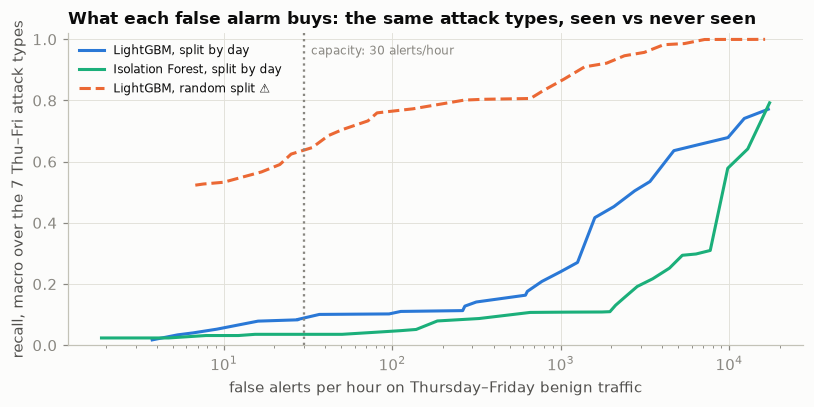

In [10]:
GRID_FPR = np.geomspace(1e-4, 0.3, 30)

def sweep(score, calib_mask, eval_mask, types=UNSEEN):
    out = []
    for f in GRID_FPR:
        thr = np.quantile(score[calib_mask], 1 - f)
        a = score >= thr
        fpr_ = a[eval_mask & (y == 0)].mean()
        rec = np.mean([a[eval_mask & (label == l)].mean() for l in types])
        out.append((fpr_ * benign_per_hour_test, rec))
    return np.array(out)

curves = {"LightGBM, split by day": (sweep(s_lgb, calib, test_d), SERIES[0], "-"),
          "Isolation Forest, split by day": (sweep(s_if, calib, test_d), SERIES[2], "-"),
          "LightGBM, random split ⚠": (sweep(s_rand, r_calib, r_test), SERIES[1], "--")}
fig, ax = plt.subplots(figsize=(7.5, 3.8))
for name, (c, color, ls) in curves.items():
    ax.plot(c[:, 0], c[:, 1], ls, lw=2, color=color, label=name)
ax.axvline(ANALYST_CAPACITY_PER_HOUR, color=MUTED, ls=":", lw=1.5)
ax.text(ANALYST_CAPACITY_PER_HOUR * 1.1, 0.95, f"capacity: {ANALYST_CAPACITY_PER_HOUR} alerts/hour", color=MUTED, fontsize=8)
ax.set_xscale("log"); ax.set_ylim(0, 1.02)
ax.set_xlabel("false alerts per hour on Thursday–Friday benign traffic"); ax.set_ylabel("recall, macro over the 7 Thu–Fri attack types")
ax.set_title("What each false alarm buys: the same attack types, seen vs never seen"); ax.legend(fontsize=8, loc="upper left")
plt.tight_layout()
need = {n: c[np.argmax(c[:, 1] >= 0.5), 0] if (c[:, 1] >= 0.5).any() else np.nan for n, (c, _, _) in curves.items()}
print("false alerts per hour needed for 50 % macro recall:", {k: (f"{v:,.0f}" if np.isfinite(v) else "never within 30 % FPR") for k, v in need.items()})

LightGBM catches **53 % of the DDoS flows** — an HTTP flood on port 80, close to Wednesday's DoS Hulk — and practically nothing else: macro recall **0.083**. The Isolation Forest catches a quarter of the 36 infiltration flows and nothing else. A second seed moves DDoS from 0.530 to 0.355: at this false-positive rate, recall on an unseen type is one draw, and the CI gate needs a margin for it. The ROC-AUC column shows the gap: web attacks rank above 97.6 % of benign flows on average, but the threshold sits above 99.95 % of them. The random split tells the board 0.643. The curve prices it: a macro recall of 50 % costs LightGBM about 2,754 false alerts an hour and the Isolation Forest 9,832; the random split promises it for 7.

## 4 · The operating point: thirty alerts an hour

*Part B · Given model · package `per_segment`; C3 owns the capacity and the incident grouping.*

The frozen threshold on Thursday and Friday; hours per file as in Section 2, alerts in flows weighted back to all traffic.

LightGBM                          Isolation Forest                        
         false alerts/hour true alerts/hour recall false alerts/hour true alerts/hour recall
segment                                                                                     
Thu am                29.0              1.0  0.001              15.3              0.0  0.000
Thu pm                34.6              0.0  0.000              15.8              1.8  0.250
Fri am                19.2              0.0  0.000              35.6              0.0  0.000
Fri pm-1              28.6             90.4  0.001               8.2              0.0  0.000
Fri pm-2              21.4         35,942.2  0.530              50.9              0.0  0.000

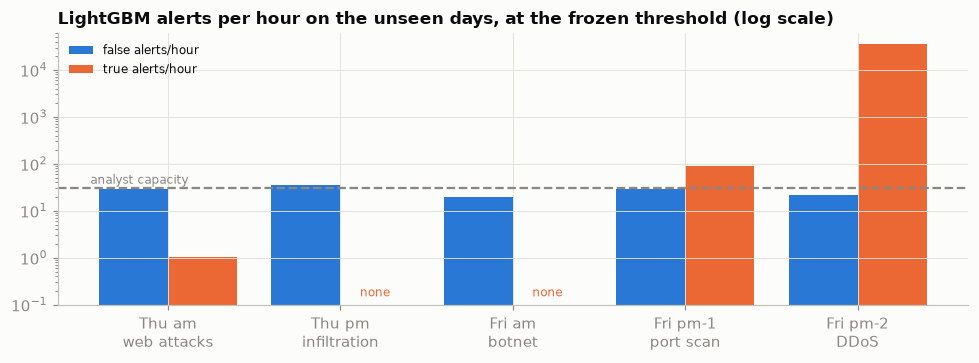

In [11]:
def per_segment(alert, mask):
    d = pd.DataFrame({"segment": flows.segment.to_numpy()[mask], "w": w[mask], "y": y[mask], "a": alert[mask]})
    g = d.groupby("segment").apply(lambda s: pd.Series({
        "false alerts": (s.w * s.a * (s.y == 0)).sum(), "true alerts": (s.w * s.a * (s.y == 1)).sum(),
        "attack flows": (s.w * (s.y == 1)).sum()}), include_groups=False)
    g = g.reindex([s for s in seg_order if s in g.index])
    hours = SEG_HOURS.reindex(g.index).to_numpy()
    return g.assign(**{"false alerts/hour": g["false alerts"] / hours, "true alerts/hour": g["true alerts"] / hours,
                       "recall": g["true alerts"] / g["attack flows"].replace(0, np.nan)})

ops = per_segment(alert_lgb, test_d)
ops_if = per_segment(alert_if, test_d)
fig, ax = plt.subplots(figsize=(9, 3.4))
x = np.arange(len(ops))
ax.bar(x - 0.2, ops["false alerts/hour"], width=0.4, color=SERIES[0], label="false alerts/hour")
ax.bar(x + 0.2, ops["true alerts/hour"].where(ops["true alerts/hour"] > 0), width=0.4, color=SERIES[1], label="true alerts/hour")
for xi, v in zip(x, ops["true alerts/hour"]):
    if v == 0:
        ax.text(xi + 0.2, 0.15, "none", ha="center", color=SERIES[1], fontsize=8)
ax.axhline(ANALYST_CAPACITY_PER_HOUR, color=MUTED, ls="--", lw=1.5)
ax.text(-0.45, ANALYST_CAPACITY_PER_HOUR * 1.25, "analyst capacity", color=MUTED, fontsize=8)
ax.set_yscale("log"); ax.set_ylim(0.1, None); ax.set_xticks(x, [f"{s}\n{t}" for s, t in zip(ops.index, ["web attacks", "infiltration", "botnet", "port scan", "DDoS"])])
ax.set_title("LightGBM alerts per hour on the unseen days, at the frozen threshold (log scale)"); ax.legend(fontsize=8)
plt.tight_layout()
both = pd.concat({"LightGBM": ops[["false alerts/hour", "true alerts/hour", "recall"]],
                   "Isolation Forest": ops_if[["false alerts/hour", "true alerts/hour", "recall"]]}, axis=1)
display(show(both, {(m, "recall"): "{:.3f}" for m in ["LightGBM", "Isolation Forest"]}, default="{:,.1f}"))

**False alerts hold** at 19–35 an hour, Thursday afternoon 15 % over capacity. **Missed attacks raise nothing**: one true alert an hour for the web attacks, none for the infiltration and botnet, 90 for the port scan. **The caught attack floods the queue**: 35,942 true alerts an hour in the DDoS. A per-flow queue is the wrong unit; alerts must become incidents (by source, target and time window), which needs the addresses and timestamps this copy lacks (task C3).

## 5 · The traps ⚠

*Part B · Given model · read; C1 turns each trap into a test.*

Four things a careless version of this notebook would have done; each makes the detector look better than the evidence allows.

**Trap 1 — the random split.** Shuffle all five days and every attack type sits on both sides: the model is tested on attacks it has seen, as in most published scores on this dataset.

In [12]:
acc_rand = ((s_rand[r_test] >= 0.5) == y[r_test]).mean()
auc_rand = roc_auc_score(y[r_test], s_rand[r_test])
auc_day = roc_auc_score(y[test_d], s_lgb[test_d])
wrec = lambda a, m: np.average(a[m & (y == 1)], weights=w[m & (y == 1)])
print(f"random 70/30 split · accuracy at 0.5 {acc_rand:.2%} · ROC-AUC {auc_rand:.4f} · attack-flow recall at the budget "
      f"{wrec(alert_rand, r_test):.1%} (all types, weighted to full traffic) · macro over the Thu–Fri types {rec_rand.reindex(UNSEEN).mean():.1%}")
print(f"split by day         · ROC-AUC {auc_day:.4f} · attack-flow recall at the budget {wrec(alert_lgb, test_d):.1%} (weighted) · "
      f"macro over the Thu–Fri types {rec_lgb.mean():.1%}")

random 70/30 split · accuracy at 0.5 98.32% · ROC-AUC 0.9985 · attack-flow recall at the budget 86.9% (all types, weighted to full traffic) · macro over the Thu–Fri types 64.3%
split by day         · ROC-AUC 0.8612 · attack-flow recall at the budget 23.4% (weighted) · macro over the Thu–Fri types 8.3%


Same model, same features, same threshold rule: 98.32 % accuracy and ROC-AUC 0.9985 at random, ROC-AUC 0.8612 by day, and macro recall at capacity on the same seven types falls from 64.3 % to 8.3 %. Put the second number in front of the board.

**Trap 2 — duplicates across train and test.** One flow in nine is a copy, and copies on both sides of a split are supposed to flatter the score. Measure it.

In [13]:
fp = flows.fp.to_numpy()
copy_rand = np.isin(fp, np.unique(fp[r_fit])) & r_test
copy_day = np.isin(flow_index.fp[flow_index.day.isin(TEST_DAYS)].to_numpy(), flow_index.fp[flow_index.day.isin(TRAIN_DAYS)].to_numpy())
lab_test_all = flow_index.label[flow_index.day.isin(TEST_DAYS)].astype(str).to_numpy()
print(f"random split: {copy_rand[r_test].mean():.1%} of test flows have an exact copy in training "
      f"({copy_rand[r_test & (y == 1)].mean():.1%} of attack flows)")
print(f"split by day: {copy_day.mean():.1%} of Thursday–Friday flows already occur on Monday–Wednesday "
      f"(attack flows among them: {int((copy_day & (lab_test_all != 'BENIGN')).sum())})")
tiny = ((flows["Total Fwd Packets"] + flows["Total Backward Packets"]) <= 2).to_numpy()
print(f"attack flows with two packets or fewer: {tiny[copy_rand & (y == 1)].mean():.0%} of those with a copy, "
      f"{tiny[r_test & ~copy_rand & (y == 1)].mean():.0%} of novel ones")
print("random split, counted on sample flows (unweighted):")
for name, m_ in [("all random-test flows", r_test), ("novel flows only", r_test & ~copy_rand), ("flows with a copy in training", copy_rand)]:
    print(f"  {name:30s} accuracy at 0.5 {((s_rand[m_] >= 0.5) == y[m_]).mean():.2%} · attack recall at the budget "
          f"{alert_rand[m_ & (y == 1)].mean():.1%} · false-positive rate {alert_rand[m_ & (y == 0)].mean():.3%}")
# the reflex fix, measured: de-duplicate the sample first, then split at random
t0 = time.time()
dd = ~flows.duplicated("fp").to_numpy()
i_tr2, _ = train_test_split(np.flatnonzero(dd), test_size=0.3, random_state=SEED, stratify=label[dd])
d_train = np.zeros(len(y), bool); d_train[i_tr2] = True
d_test = dd & ~d_train
d_calib = d_train & (y == 0) & (np.random.default_rng(SEED + 1).random(len(y)) < CALIB_FRAC)
s_dd = fit_lgb(d_train & ~d_calib, FEATURES).predict_proba(X[FEATURES])[:, 1]
_, alert_dd, _, _ = at_budget(s_dd, d_calib, d_test)
print(f"  de-duplicate, then split       accuracy at 0.5 {((s_dd[d_test] >= 0.5) == y[d_test]).mean():.2%} · attack recall at the budget "
      f"{alert_dd[d_test & (y == 1)].mean():.1%} · {(~dd).sum():,} sample flows removed, "
      f"{(~dd & (label == 'PortScan')).sum() / (label == 'PortScan').sum():.1%} of the sampled port scan  ({time.time() - t0:.0f}s)")

random split: 5.5% of test flows have an exact copy in training (13.8% of attack flows)
split by day: 5.1% of Thursday–Friday flows already occur on Monday–Wednesday (attack flows among them: 0)
attack flows with two packets or fewer: 93% of those with a copy, 25% of novel ones
random split, counted on sample flows (unweighted):
  all random-test flows          accuracy at 0.5 98.32% · attack recall at the budget 88.5% · false-positive rate 0.059%
  novel flows only               accuracy at 0.5 98.62% · attack recall at the budget 95.3% · false-positive rate 0.059%
  flows with a copy in training  accuracy at 0.5 93.06% · attack recall at the budget 45.6% · false-positive rate 0.081%


  de-duplicate, then split       accuracy at 0.5 99.51% · attack recall at the budget 94.8% · 30,856 sample flows removed, 10.7% of the sampled port scan  (24s)


Here they do **not** flatter: counted on sample flows, the random split recalls 95.3 % of novel attack flows and 45.6 % of those with a copy in training. The copies are degenerate — 93 % have two packets or fewer, against 25 % of novel attack flows — and benign traffic makes such flows too. The trap is the reflex fix, measured here: de-duplicate the sample, then split, and accuracy rises from 98.32 % to 99.51 % and recall at the budget from 88.5 % to 94.8 % — because you deleted the flows nobody can classify, 10.7 % of the sampled port scan among them (42.9 % of the full one). De-duplicate the training set only, and report on all flows. The split by day is clean: 5.1 % of Thursday–Friday flows occurred earlier in the week, none of them an attack.

**Trap 3 — features that identify the capture, not the attack.** Destination port and initial TCP window look like protocol facts; here they are facts about the testbed.

In [14]:
t0 = time.time()
s_cap = fit_lgb(fit, ALL_FEATURES).predict_proba(X[ALL_FEATURES])[:, 1]
_, _, fpr_cap, rec_cap = at_budget(s_cap, calib, test_d)
s_only = fit_lgb(r_fit, CAPTURE_FEATURES).predict_proba(X[CAPTURE_FEATURES])[:, 1]
_, alert_only, _, _ = at_budget(s_only, r_calib, r_test)
display(show(pd.DataFrame({"without capture features": rec_lgb, "with capture features ⚠": rec_cap}).T
             .assign(macro=lambda d: d.mean(axis=1))))
print(f"split by day, macro recall at the budget: {rec_lgb.mean():.3f} → {rec_cap.mean():.3f} with {', '.join(CAPTURE_FEATURES)}")
print(f"random split, ONLY those {len(CAPTURE_FEATURES)} columns: ROC-AUC {roc_auc_score(y[r_test], s_only[r_test]):.4f}, "
      f"attack-flow recall at the budget {wrec(alert_only, r_test):.1%}  ({time.time() - t0:.0f}s)")
for col, val in [("Init_Win_bytes_forward", 29200), ("Destination Port", 80), ("Destination Port", 444)]:
    share = flows.assign(v=flows[col] == val).groupby("label", observed=True).v.mean()
    print(f"  {col} = {val}: " + ", ".join(f"{k} {v:.0%}" for k, v in share.sort_values(ascending=False).items() if v >= 0.5))

,Bot,DDoS,Infiltration,PortScan,Web Attack – Brute Force,Web Attack – Sql Injection,Web Attack – XSS,macro
without capture features,0.000,0.530,0.000,0.001,0.000,0.048,0.003,0.083
with capture features ⚠,0.000,0.633,0.000,0.004,0.893,0.905,0.926,0.480


split by day, macro recall at the budget: 0.083 → 0.480 with Destination Port, Init_Win_bytes_forward, Init_Win_bytes_backward
random split, ONLY those 3 columns: ROC-AUC 0.9965, attack-flow recall at the budget 60.3%  (29s)
  Init_Win_bytes_forward = 29200: Web Attack – XSS 96%, Web Attack – Brute Force 91%, DoS Slowhttptest 77%, DoS GoldenEye 71%, DoS slowloris 67%, Web Attack – Sql Injection 57%, PortScan 51%, SSH-Patator 51%, FTP-Patator 50%
  Destination Port = 80: DDoS 100%, DoS Hulk 100%, DoS GoldenEye 100%, DoS Slowhttptest 100%, DoS slowloris 100%, Web Attack – XSS 100%, Web Attack – Sql Injection 100%, Web Attack – Brute Force 100%
  Destination Port = 444: Heartbleed 100%, Infiltration 100%


Three columns lift macro recall on the unseen days from 0.083 to 0.480, and on the random split they *alone* reach ROC-AUC 0.9965. Nothing about a web attack is in them: the web attacks hit port 80 of the server Wednesday's DoS hit, from the same Kali machine (window 29200, the Linux default, on 91 % of web brute-force and 96 % of XSS flows), and the infiltration shares port 444 with Heartbleed. The detector learns *this attacker on this network*. Keep these columns out of the model and use them as forensic evidence, as Trap 4 does.

**Trap 4 — label noise from flow construction.** Labels came from the attack schedule; CICFlowMeter cut the flows. Where the two disagree, the label is wrong — in both directions.

In [15]:
zp = flows.zero_payload.to_numpy()
tbl = pd.DataFrame({"label": label, "zero payload": zp, "alert": alert_lgb})[test_d & (y == 1)]
zp_tbl = tbl.groupby(["label", "zero payload"]).alert.agg(flows="size", recall="mean").unstack()
display(show(zp_tbl, {c: "{:,.0f}" for c in zp_tbl.columns if c[0] == "flows"}))
t0 = time.time()
fit_clean = fit & ~((y == 1) & zp)                     # drop attack-labelled flows that carry no payload at all
s_clean = fit_lgb(fit_clean, FEATURES).predict_proba(X[FEATURES])[:, 1]
_, _, fpr_clean, rec_clean = at_budget(s_clean, calib, test_d)
print(f"training without {int((fit & (y == 1) & zp).sum()):,} payload-less attack flows: macro recall {rec_lgb.mean():.3f} → "
      f"{rec_clean.mean():.3f} · realised FPR {fpr_lgb:.4%} → {fpr_clean:.4%} · AUROC (macro) "
      f"{auroc_by_label(s_lgb, test_d).mean():.3f} → {auroc_by_label(s_clean, test_d).mean():.3f}  ({time.time() - t0:.0f}s)")
print(f"random split, attack recall at the budget: flows with payload {alert_rand[r_test & (y == 1) & ~zp].mean():.1%} · "
      f"payload-less flows {alert_rand[r_test & (y == 1) & zp].mean():.1%}")
# the other direction: attack traffic labelled BENIGN, found with the testbed's own fingerprints (forensics, not features)
nmap_like = ((flows["Init_Win_bytes_forward"] == 1024) & (flows["Total Fwd Packets"] <= 2)).to_numpy()       # Nmap SYN-scan probe
reversed_ddos = ((flows["Init_Win_bytes_forward"] == 229) & (flows["Destination Port"] >= 1024)).to_numpy()  # victim's window, attacker's port
ben_mask = (y == 0)
sig = pd.DataFrame({"segment": flows.segment.to_numpy(), "w": w, "nmap": nmap_like, "rev": reversed_ddos})[ben_mask]
sig_tbl = sig.groupby("segment").apply(lambda d: pd.Series({
    "BENIGN flows with Nmap's SYN window": (d.w * d.nmap).sum(), "share ": (d.w * d.nmap).sum() / d.w.sum(),
    "BENIGN flows that look like reversed DDoS": (d.w * d.rev).sum(), "share": (d.w * d.rev).sum() / d.w.sum()}), include_groups=False)
display(show(sig_tbl.reindex(seg_order), {"BENIGN flows with Nmap's SYN window": "{:,.0f}", "BENIGN flows that look like reversed DDoS": "{:,.0f}",
                                          "share ": "{:.2%}", "share": "{:.2%}"}))
mislab = nmap_like | reversed_ddos
for name, a in [("LightGBM", alert_lgb), ("Isolation Forest", alert_if)]:
    fa = a & test_d & (y == 0)
    print(f"{name}: {np.average(mislab[fa], weights=w[fa]):.0%} of its Thursday–Friday 'false' alerts fall in these two groups")

flows        recall       
zero payload                 False  True   False  True 
label                                                  
Bot                          1,964      2  0.000  0.000
DDoS                        20,000         0.530       
Infiltration                    36         0.000       
PortScan                    19,917     83  0.001  0.108
Web Attack – Brute Force       151  1,356  0.000  0.000
Web Attack – Sql Injection      12      9  0.083  0.000
Web Attack – XSS                24    628  0.083  0.000

training without 15,763 payload-less attack flows: macro recall 0.083 → 0.126 · realised FPR 0.0507% → 0.0397% · AUROC (macro) 0.857 → 0.846  (21s)
random split, attack recall at the budget: flows with payload 96.4% · payload-less flows 51.8%


,BENIGN flows with Nmap's SYN window,share,BENIGN flows that look like reversed DDoS,share
segment,,,,
Mon,130,0.02%,778,0.15%
Tue,150,0.03%,841,0.19%
Wed,159,0.04%,779,0.18%
Thu am,50,0.03%,291,0.17%
Thu pm,"63,174",21.89%,580,0.20%
Fri am,95,0.05%,265,0.14%
Fri pm-1,30,0.02%,392,0.31%
Fri pm-2,15,0.02%,"26,127",26.74%


LightGBM: 1% of its Thursday–Friday 'false' alerts fall in these two groups
Isolation Forest: 19% of its Thursday–Friday 'false' alerts fall in these two groups


(1) Of 1,507 web brute-force flows, 1,356 carry no payload; the honest denominator is the 151 that do. (2) In the random split, attack flows with payload are recalled at 96.4 %, payload-less ones at 51.8 %. (3) Training without the 15,763 payload-less attack flows cuts the realised false-positive rate from 0.0507 % to 0.0397 % and lifts macro recall from 0.083 to 0.126, but macro ROC-AUC falls (0.857 → 0.846) and the seed alone moved recall by 0.025: a lead to record in the model card, not a result. (4) The opposite error: about 63,000 Thursday-afternoon flows labelled BENIGN carry Nmap's 1,024-byte SYN-scan window (21.9 % of that file's benign flows, 0.05 % or less elsewhere) — the infiltration's published second step, an internal port scan, was never labelled — and about 26,000 BENIGN flows in the DDoS file carry the victim's window towards the attackers' ports: DDoS connections seen from the other end. 19 % of the Isolation Forest's "false" alerts (1 % of LightGBM's) fall in these two groups.

## 6 · ATT&CK as the knowledge base

*Part B · Given model · package the ATT&CK mapping and the alert pack; E1 builds it properly, E4 tests the coverage hypothesis.*

A SOC triages *what kind of attack, and what next*. MITRE ATT&CK is the shared vocabulary: techniques (T1110.001, *Password Guessing*) under tactics (*Credential Access*). The KB maps the labels to both, with a playbook line per tactic (three mappings marked approximate), and is used twice: to predict where the detector is blind, and to enrich the alert.

In [16]:
KB = pd.DataFrame([
    ("FTP-Patator", "T1110.001", "Brute Force: Password Guessing", "Credential Access", "exact"),
    ("SSH-Patator", "T1110.001", "Brute Force: Password Guessing", "Credential Access", "exact"),
    ("DoS slowloris", "T1499.002", "Endpoint Denial of Service: Service Exhaustion Flood", "Impact", "exact"),
    ("DoS Slowhttptest", "T1499.002", "Endpoint Denial of Service: Service Exhaustion Flood", "Impact", "exact"),
    ("DoS Hulk", "T1499.002", "Endpoint Denial of Service: Service Exhaustion Flood", "Impact", "exact"),
    ("DoS GoldenEye", "T1499.002", "Endpoint Denial of Service: Service Exhaustion Flood", "Impact", "exact"),
    ("Heartbleed", "T1190", "Exploit Public-Facing Application", "Initial Access", "exact"),
    ("Web Attack – Brute Force", "T1110.001", "Brute Force: Password Guessing", "Credential Access", "exact"),
    ("Web Attack – XSS", "T1189", "Drive-by Compromise", "Initial Access", "approximate: ATT&CK has no XSS technique"),
    ("Web Attack – Sql Injection", "T1190", "Exploit Public-Facing Application", "Initial Access", "exact"),
    ("Infiltration", "T1204.002", "User Execution: Malicious File", "Execution", "approximate: multi-stage, then T1046 inside"),
    ("Bot", "T1071.001", "Application Layer Protocol: Web Protocols", "Command and Control", "exact"),
    ("PortScan", "T1046", "Network Service Discovery", "Discovery", "exact"),
    ("DDoS", "T1499.002", "Endpoint Denial of Service: Service Exhaustion Flood", "Impact", "approximate: LOIC HTTP flood on port 80; T1498.001 if read as volumetric"),
], columns=["label", "technique", "technique name", "tactic", "mapping"]).set_index("label")
PLAYBOOK = {  # tactic → (flow evidence to check, first response); written from the ATT&CK technique pages
    "Credential Access": ("many short sessions to one login service from one source", "rate-limit or lock the account; look for a success after the failures"),
    "Impact": ("connection or packet rate to one service far above its baseline", "rate-limit at the edge or WAF; check service health; call upstream scrubbing"),
    "Initial Access": ("unusual request sizes or payloads to a public-facing service", "check the service logs and patch level; look for data leaving"),
    "Execution": ("an internal host opens a new outbound session after a download", "isolate the host and image it"),
    "Command and Control": ("periodic small web sessions from an internal host to one external server", "isolate the host; block the destination"),
    "Discovery": ("one source touching many ports or hosts with one- or two-packet flows", "identify the scanner; is it an authorised scan?"),
}
display(KB)
print(f"{len(KB)} labels → {KB.technique.nunique()} techniques → {KB.tactic.nunique()} tactics")
seen_tactics, seen_techniques = set(KB.loc[SEEN, "tactic"]), set(KB.loc[SEEN, "technique"])
auc_lgb_u = auroc_by_label(s_lgb, test_d)
cov = KB.loc[UNSEEN, ["technique", "tactic", "mapping"]].assign(
    **{"technique seen in training": lambda d: d.technique.isin(seen_techniques),
       "tactic seen in training": lambda d: d.tactic.isin(seen_tactics),
       "LightGBM AUROC": auc_lgb_u, "LightGBM recall at budget": rec_lgb})
display(show(cov))
for level in ["tactic", "technique"]:
    g = cov.groupby(f"{level} seen in training")["LightGBM AUROC"].agg(["size", "mean"])
    print(f"mean AUROC by {level} coverage: " + " · ".join(f"seen={k}: {v['mean']:.3f} over {int(v['size'])} types" for k, v in g.iterrows()))

,technique,technique name,tactic,mapping
label,,,,
FTP-Patator,T1110.001,Brute Force: Password Guessing,Credential Access,exact
SSH-Patator,T1110.001,Brute Force: Password Guessing,Credential Access,exact
DoS slowloris,T1499.002,Endpoint Denial of Service: Service Exhaustion Flood,Impact,exact
DoS Slowhttptest,T1499.002,Endpoint Denial of Service: Service Exhaustion Flood,Impact,exact
DoS Hulk,T1499.002,Endpoint Denial of Service: Service Exhaustion Flood,Impact,exact
DoS GoldenEye,T1499.002,Endpoint Denial of Service: Service Exhaustion Flood,Impact,exact
Heartbleed,T1190,Exploit Public-Facing Application,Initial Access,exact
Web Attack – Brute Force,T1110.001,Brute Force: Password Guessing,Credential Access,exact
Web Attack – XSS,T1189,Drive-by Compromise,Initial Access,approximate: ATT&CK has no XSS technique


14 labels → 7 techniques → 6 tactics


,technique,tactic,mapping,technique seen in training,tactic seen in training,LightGBM AUROC,LightGBM recall at budget
label,,,,,,,
Bot,T1071.001,Command and Control,exact,False,False,0.552,0.000
DDoS,T1499.002,Impact,approximate: LOIC HTTP flood on port 80; T1498.001 if read as volumetric,True,True,0.968,0.530
Infiltration,T1204.002,Execution,"approximate: multi-stage, then T1046 inside",False,False,0.780,0.000
PortScan,T1046,Discovery,exact,False,False,0.772,0.001
Web Attack – Brute Force,T1110.001,Credential Access,exact,True,True,0.976,0.000
Web Attack – Sql Injection,T1190,Initial Access,exact,True,True,0.976,0.048
Web Attack – XSS,T1189,Initial Access,approximate: ATT&CK has no XSS technique,False,True,0.976,0.003


mean AUROC by tactic coverage: seen=False: 0.701 over 3 types · seen=True: 0.974 over 4 types
mean AUROC by technique coverage: seen=False: 0.770 over 4 types · seen=True: 0.973 over 3 types


In [17]:
# Enrichment as the baseline can do it: name the nearest KNOWN attack, and look its tactic up in the KB
t0 = time.time()
seen_att = fit & (y == 1)
m_near = lgb.LGBMClassifier(**{**LGB_PARAMS, "n_estimators": 100}).fit(X.loc[seen_att, FEATURES], label[seen_att])
te_att = test_d & (y == 1)
nearest = m_near.predict(X.loc[te_att, FEATURES])
true_tactic = KB.loc[label[te_att], "tactic"].to_numpy()
route = pd.DataFrame({"label": label[te_att], "nearest known attack": nearest,
                      "KB": KB.loc[nearest, "tactic"].to_numpy() == true_tactic,
                      "no KB": true_tactic == KB.loc[SEEN, "tactic"].value_counts().idxmax()})
routing = route.groupby("label").agg(**{"most common nearest attack": ("nearest known attack", lambda s: s.value_counts().idxmax()),
                                        "right tactic, no KB (default playbook)": ("no KB", "mean"),
                                        "right tactic, KB via nearest attack": ("KB", "mean")})
routing.loc["macro"] = ["", routing.iloc[:, 1].mean(), routing.iloc[:, 2].mean()]
display(show(routing, default="{:.2f}"))
print(f"default playbook = the most common tactic among training attacks: {KB.loc[SEEN, 'tactic'].value_counts().idxmax()} ({time.time() - t0:.0f}s)")

,most common nearest attack,"right tactic, no KB (default playbook)","right tactic, KB via nearest attack"
label,,,
Bot,SSH-Patator,0.00,0.00
DDoS,DoS Hulk,1.00,1.00
Infiltration,DoS GoldenEye,0.00,0.00
PortScan,DoS slowloris,0.00,0.00
Web Attack – Brute Force,DoS slowloris,0.00,0.14
Web Attack – Sql Injection,DoS GoldenEye,0.00,0.00
Web Attack – XSS,DoS slowloris,0.00,0.00
macro,,0.14,0.16


default playbook = the most common tactic among training attacks: Impact (9s)


In [18]:
# One enriched alert, as a triage queue (or an LLM in task S1) would receive it: evidence, context, no ground truth
ref = X.loc[calib, FEATURES]
med, iqr = ref.median(), (ref.quantile(0.75) - ref.quantile(0.25)).replace(0, 1.0)
cand = np.flatnonzero(alert_lgb & (flows.segment == "Thu am").to_numpy())
i = cand[np.argmax(s_lgb[cand])]
z = ((X.iloc[i][FEATURES] - med) / iqr).abs().sort_values(ascending=False).head(5)
near = m_near.predict(X.iloc[[i]][FEATURES])[0]
pack = {"alert": {"segment": flows.segment.iloc[i], "score": round(float(s_lgb[i]), 3), "threshold": round(float(thr_lgb), 3)},
        "flow_evidence": {f: {"value": round(float(X.iloc[i][f]), 1), "benign_median": round(float(med[f]), 1)} for f in z.index},
        "nearest_known_attack": near,
        "attck": {"technique": KB.loc[near, "technique"], "name": KB.loc[near, "technique name"], "tactic": KB.loc[near, "tactic"],
                  "check": PLAYBOOK[KB.loc[near, "tactic"]][0], "first_response": PLAYBOOK[KB.loc[near, "tactic"]][1]}}
print(json.dumps(pack, indent=1, ensure_ascii=False))
print(f"ground truth (hidden from the analyst): {label[i]} · tactic {KB.loc[label[i], 'tactic'] if label[i] in KB.index else '—'}")

{
 "alert": {
  "segment": "Thu am",
  "score": 0.998,
  "threshold": 0.928
 },
 "flow_evidence": {
  "Fwd Packets/s": {
   "value": 48780.5,
   "benign_median": 62.7
  },
  "Flow Packets/s": {
   "value": 48780.5,
   "benign_median": 114.2
  },
  "Total Backward Packets": {
   "value": 0.0,
   "benign_median": 2.0
  },
  "Subflow Bwd Packets": {
   "value": 0.0,
   "benign_median": 2.0
  },
  "Flow Bytes/s": {
   "value": 341463.4,
   "benign_median": 4542.3
  }
 },
 "nearest_known_attack": "FTP-Patator",
 "attck": {
  "technique": "T1110.001",
  "name": "Brute Force: Password Guessing",
  "tactic": "Credential Access",
  "check": "many short sessions to one login service from one source",
  "first_response": "rate-limit or lock the account; look for a success after the failures"
 }
}
ground truth (hidden from the analyst): BENIGN · tactic —


Read the coverage table as a hypothesis. The four unseen types whose **tactic** appears in training score a mean ROC-AUC of 0.974; the three whose tactic never appeared (Command and Control, Discovery, Execution) score 0.701, the botnet close to a coin toss. By **technique** — the DDoS is an HTTP flood on port 80, so it maps to T1499.002 like the DoS tools — the three seen types score 0.973 and the four unseen 0.770. Seven types, three of them web attacks with the same ROC-AUC, cannot prove that ATT&CK coverage predicts blind spots; task E4 tests it.

Enrichment is a harder sell. Looking up the tactic of the nearest *known* attack routes 0.16 of unseen attack flows (macro) to the right playbook, against 0.14 for sending everything to *Impact*: a KB keyed on yesterday's labels cannot name today's technique. The enriched alert shows the danger: the top Thursday-morning alert is **benign**, and the pack dresses it as *Brute Force: Password Guessing* with a confident playbook. E1 asks whether richer ATT&CK evidence beats this floor; S1 asks an LLM to say *insufficient evidence* when that is the truth.

# Part C — Productionise it

*Sections 7–10: this is your assignment.*

## 7 · After deployment: the alert rate per hour, and the attacks that move nothing

*Part C · Productionise · what your monitoring plan must catch; reuse `psi` and `psi_cat` (C5).*

Freeze model and threshold and run Thursday and Friday as production. Two clocks, as in task 02: **now** — port mix, flow duration, score (PSI against Monday–Wednesday, whose own rows give the reference band) and the alert rate; **later** — recall and precision, once incidents are investigated.

,PSI · port mix,PSI · flow duration,PSI · model score,false alerts/hour,true alerts/hour,recall,alerts/hour ÷ capacity,precision
segment,,,,,,,,
Mon,0.17,0.07,0.01,,,,,
Tue,0.16,0.07,0.03,,,,,
Wed,0.18,0.09,0.61,,,,,
Thu am,0.12,0.06,0.02,29,1,0.00,1.00,0.03
Thu pm,0.33,0.25,0.10,35,0,0.00,1.15,0.00
Fri am,0.16,0.07,0.02,19,0,0.00,0.64,0.00
Fri pm-1,1.05,0.87,0.79,29,90,0.00,3.97,0.76
Fri pm-2,0.76,0.80,1.23,21,"35,942",0.53,1198.79,1.00


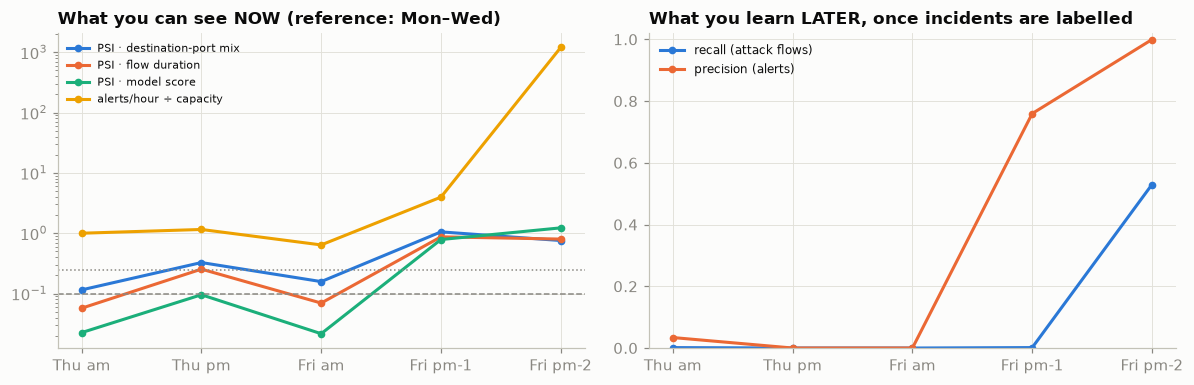

In [19]:
def psi(ref, cur, ref_w, cur_w, bins=10):
    edges = np.unique(np.quantile(ref, np.linspace(0, 1, bins + 1))); edges[0], edges[-1] = -np.inf, np.inf
    r = np.histogram(ref, edges, weights=ref_w)[0] / ref_w.sum() + 1e-6
    c = np.histogram(cur, edges, weights=cur_w)[0] / cur_w.sum() + 1e-6
    return float(np.sum((c - r) * np.log(c / r)))

def psi_cat(ref, cur, ref_w, cur_w, top=10):
    cats = pd.Series(ref_w, index=ref).groupby(level=0).sum().nlargest(top).index
    r = pd.Series(ref_w, index=np.where(np.isin(ref, cats), ref, -1)).groupby(level=0).sum() / ref_w.sum()
    c = pd.Series(cur_w, index=np.where(np.isin(cur, cats), cur, -1)).groupby(level=0).sum() / cur_w.sum()
    r, c = r.align(c, fill_value=0)
    r, c = r + 1e-6, c + 1e-6
    return float(np.sum((c - r) * np.log(c / r)))

log_dur = np.log1p(X["Flow Duration"].clip(lower=0).to_numpy())
port = X["Destination Port"].to_numpy()
rows = []
for sname in seg_order:
    m_ = (flows.segment == sname).to_numpy()
    rows.append({"segment": sname,
                 "PSI · port mix": psi_cat(port[train_d], port[m_], w[train_d], w[m_]),
                 "PSI · flow duration": psi(log_dur[train_d], log_dur[m_], w[train_d], w[m_]),
                 "PSI · model score": psi(s_lgb[calib], s_lgb[m_], w[calib], w[m_])})
monitor = pd.DataFrame(rows).set_index("segment")
monitor = monitor.join(ops[["false alerts/hour", "true alerts/hour", "recall"]])
monitor["alerts/hour ÷ capacity"] = (monitor["false alerts/hour"] + monitor["true alerts/hour"]) / ANALYST_CAPACITY_PER_HOUR
monitor["precision"] = monitor["true alerts/hour"] / (monitor["false alerts/hour"] + monitor["true alerts/hour"])

stream = monitor.loc[[s for s in seg_order if SEG_DAY[seg_order.index(s)] in TEST_DAYS]]
fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
ax = axes[0]
for i, (c, lab_) in enumerate([("PSI · port mix", "PSI · destination-port mix"), ("PSI · flow duration", "PSI · flow duration"),
                               ("PSI · model score", "PSI · model score"), ("alerts/hour ÷ capacity", "alerts/hour ÷ capacity")]):
    ax.plot(stream.index, stream[c].clip(lower=1e-3), "-o", ms=4, lw=2, color=SERIES[i], label=lab_)
ax.axhline(0.10, color=MUTED, ls="--", lw=1); ax.axhline(0.25, color=MUTED, ls=":", lw=1)
ax.set_yscale("log"); ax.set_title("What you can see NOW (reference: Mon–Wed)"); ax.legend(fontsize=7)
ax = axes[1]
ax.plot(stream.index, stream.recall, "-o", ms=4, lw=2, color=SERIES[0], label="recall (attack flows)")
ax.plot(stream.index, stream.precision, "-o", ms=4, lw=2, color=SERIES[1], label="precision (alerts)")
ax.set_ylim(0, 1.02); ax.set_title("What you learn LATER, once incidents are labelled"); ax.legend(fontsize=8)
plt.tight_layout()
display(show(monitor, {"false alerts/hour": "{:,.0f}", "true alerts/hour": "{:,.0f}"}, default="{:.2f}"))

**Thursday morning** (web attacks) and **Friday morning** (botnet) move nothing: port-mix PSI 0.12 and 0.16, no higher than the training days' own 0.16–0.18; score PSI 0.02; recall practically zero. This is task 02's silent failure in security form: a low-volume attack with an unseen tactic is invisible to the model *and* to the drift monitor. **Thursday afternoon** moved (port mix 0.33, flow duration 0.25) while recall on the 36 labelled infiltration flows was zero: the drift matches the unlabelled internal scan from Trap 4, which the input monitor saw and the labels missed. **Friday afternoon** is loud: the port scan pushes every PSI to 0.79 or more while the model raises 90 true alerts an hour, and the DDoS hour runs at 1,199 times capacity.

So the monitoring plan (C5) alarms on the alert rate, treats port-mix drift as a detector in its own right, and red-teams the ATT&CK tactics training never covered.

## 8 · The module spine for this project

*Part C · Productionise · the targets your system must meet, with this notebook's numbers.*

The ten principles every project covers, updated with what this notebook measured.

| Spine | In this project |
|---|---|
| Package and container (S02–S03) | `src/ids/` (`features.py`: dead columns out, ±inf → missing, no address columns, no capture features); `POST /score` per flow; compose with Prometheus |
| Monitoring (S04) | Alerts per hour against 30 (19–35 false alerts an hour on unseen days; 35,942 true in the DDoS hour): alarm above 3× capacity. PSI on port mix and flow duration (training days 0.16–0.18 and 0.07–0.09): warn at 0.25, alarm at 0.5. Analyst feedback; throughput |
| CI/CD gate (S05) | Macro recall over the seven unseen types at a 0.0514 % false-positive rate on the fingerprinted Thursday–Friday holdout (0.083; 0.058 with another seed): gate on a multi-seed mean with a margin, and on a realised false-positive rate below 0.07 % |
| MLflow tracking and registry (S06) | Day split, features, SHA-256 of cleaning rules and holdout, seed, threshold; `champion` alias |
| Offline / online training and serving | Online stream scoring, incident grouping; nightly retraining on labelled incidents |
| Data and model drift | Novel attack types (unseen tactic: ROC-AUC 0.701 against 0.974); weekday benign mix (port-mix PSI 0.12–0.33 on calm files); attack traffic labelled benign |
| Knowledge base and context (S07–S09) | ATT&CK: 14 labels → 7 techniques → 6 tactics, three mappings approximate; coverage hypothesis (ROC-AUC 0.974 against 0.701 by tactic, 0.973 against 0.770 by technique); routing floor 0.14 without KB, 0.16 with nearest-attack context |
| GenAI and context engineering (S10–S11) | Triage note from the context pack only, able to say *insufficient evidence* (the top Thursday-morning alert is benign) |
| Governance | Flow logs carry IP addresses: keyed-hash pseudonymisation; CC0 set by a non-owner, so follow CIC's terms; NIS2 incident reporting |

## 9 · Student tasks

*Part C · Productionise · your assignment.*

This is an individual assignment: you pick one task from the catalogue, claimed first come, first served, so no other student works on it. **The model is given:** you package, evaluate, deploy and monitor this notebook's model; you do not design, tune or replace it. Where a task re-runs training (removing a leaking input, a retraining policy, a knowledge-base ablation), run the notebook's own training code with only its inputs or configuration changed. Work in your own repository, not in this notebook. Promote code into the `src/` package layout from Session 02, keep the notebook as a thin client, and record each design decision as an ADR in `docs/decisions/`. **Required:** all *Core* tasks (C1–C5), all *Extension* tasks (E1–E4) and Stretch **S1**, the GenAI task (Sessions 10–11). No API key is provided: run it on a local open-weight model, with a free hosted tier as an optional comparison, under the data rule for this task in [`docs/llm-access.md`](../../docs/llm-access.md). The other Stretch tasks are optional and count only towards the top band. The mark rewards the quality of each task, not the number done; the criteria are in `docs/task-rubric.md`.

### Core

- **C1 — Find and fix every trap.** Drop the capture features and test the next suspects (`min_seg_size_forward`, header lengths); relabel payload-less attack flows and the Thursday-afternoon scan (Engelen et al., 2021); de-duplicate the training set only. Each fix is a test (no attack label in both train and test days; no capture feature or infinity reaches the model); report honest and naive numbers side by side.
- **C2 — Reproduce and freeze the given model.** Package the notebook's own data loading, features, training and scoring unchanged, retrain from a fresh clone with `SEED`, and show that your pipeline reproduces the numbers listed under *How this notebook is organised* within a tolerance you state. Add a data contract on the raw inputs (schema and value ranges, for example with pandera) and record any difference from the notebook in an ADR. No new features, learners or tuning.
- **C3 — Own the operating point.** Vary `ANALYST_CAPACITY_PER_HOUR` from 10 to 200; add incident grouping and restate capacity in incidents per hour; the ADR says who signed it off and what happens in the DDoS hour.
- **C4 — Package, container and gate.** `src/ids/`, a `POST /score` container, and `make ci` with a gate that scores the frozen Thursday–Friday holdout, refuses if its SHA-256 fingerprint changes, and fails below the business threshold minus a seed margin (Sessions 02, 03, 05).
- **C5 — Register, document, monitor.** MLflow, a `champion` alias, a model card (staged testbed, single attacker, label noise, licence), and a monitoring plan with the alert-rate alarm, the PSI thresholds above, analyst feedback as labels and the retraining trigger (Sessions 04, 06).

### Extension

- **E1 — The ATT&CK knowledge layer and its ablation.** Build the KB with rdflib from the ATT&CK STIX bundle (labels → techniques → tactics → data sources), settle the three approximate mappings (XSS, infiltration, DDoS) with a confidence field, validate with pySHACL, version it; measure the detector alone against alerts enriched with ATT&CK context, as playbook routing accuracy (floor: 0.14 and 0.16) and analyst minutes (Sessions 07–09).
- **E2 — Governance of the flow log.** Pseudonymisation (keyed hash, rotation, who may re-identify), retention, access; the GDPR basis for security logging (Recital 49), NIS2 duties, and the EU AI Act position.
- **E3 — Who pays for the false alarms?** Break false alerts down by destination service; if one group of users absorbs most, propose an operational fix (routing, a per-service queue or a time-limited suppression rule) without muting the service or changing the model, and cost it.
- **E4 — Leave one attack type out.** Hold out each type in turn; compare the recall matrix with the split by day, and test whether ATT&CK coverage predicts which types are missed.

### Stretch

- **S1 — A grounded triage note.** An LLM writes a note per top-50 alert from the context pack only (verdict, technique, evidence, next step; structured output, versioned prompt); evaluate on a golden set with false alarms for factuality, verdicts, prompt injection and cost (Sessions 10–11).
- **S2 — Streaming serving and its cost.** Stream → scorer → incident grouper → SIEM; measure throughput and latency; cost the DDoS hour against a calm one.
- **S3 — Retraining on new incidents.** Replay the week with nightly retraining; what does it buy, at what labelling cost?

## 10 · Hand-in checklist

*Part C · Productionise · tick every box before you submit.*

- [ ] Repository in the Session 02 layout; fresh-clone test passes; `data/` not committed; no address or time columns read
- [ ] `README.md` states the day split, the sampling rule, the capacity and how to get the data (Kaggle; CIC citation)
- [ ] Split by day only; traps removed, each with a test
- [ ] Operating point from analyst capacity, with incident grouping and the ADR
- [ ] CI gate on the fingerprinted holdout; registered model and model card; monitoring plan
- [ ] ATT&CK knowledge layer with SHACL validation and the ablation result
- [ ] One-page recommendation for the SOC lead
- [ ] Required tasks done: C1–C5, E1–E4 and S1
- [ ] GenAI task runs on a local model; any hosted run follows the data rule and logs provider, model and cost
- [ ] Reflective diary entry: what you chose, what you rejected, what evidence would change your mind

---

### Appendix — environment and references

- Python ≥ 3.11; `pandas`, `pyarrow`, `scikit-learn`, `lightgbm`, `matplotlib`, `kagglehub` (pinned in `requirements.txt`).
- Sharafaldin, I., Habibi Lashkari, A., Ghorbani, A. A. (2018). *Toward Generating a New Intrusion Detection Dataset and Intrusion Traffic Characterization.* ICISSP (CIC-IDS2017).
- Engelen, G., Rimmer, V., Joosen, W. (2021). *Troubleshooting an Intrusion Detection Dataset: the CICIDS2017 Case Study.* IEEE Security and Privacy Workshops.
- Sommer, R., Paxson, V. (2010). *Outside the Closed World: On Using Machine Learning for Network Intrusion Detection.* IEEE S&P. Arp, D. et al. (2022). *Dos and Don'ts of Machine Learning in Computer Security.* USENIX Security.
- Liu, F. T., Ting, K. M., Zhou, Z.-H. (2008). *Isolation Forest.* ICDM. Ke, G. et al. (2017). *LightGBM.* NeurIPS.
- MITRE ATT&CK Enterprise (attack.mitre.org); ATT&CK® is a registered trademark of The MITRE Corporation. CJEU C‑582/14, *Breyer* (2016).

In [20]:
print(f"python {'.'.join(map(str, __import__('sys').version_info[:3]))} · pandas {pd.__version__} · numpy {np.__version__} · "
      f"lightgbm {lgb.__version__} · scikit-learn {sklearn.__version__} · pyarrow {pa.__version__}")
print(f"notebook finished · total wall time {time.time() - T_START:.0f}s")

python 3.13.13 · pandas 3.1.0 · numpy 2.5.4 · lightgbm 4.7.0 · scikit-learn 1.9.1 · pyarrow 26.0.0
notebook finished · total wall time 187s
